# Studio 2 — Klasifikasi Sampah · K13B - Synapse

Deep Learning (IF25-40401) · Teknik Informatika ITERA · Semester Ganjil 2026/2027

**Kelompok 13**

## Anggota Kelompok
 1 Najlatika 123140078

 2 Hanifah Hasanah 123140082

 3 Muhammad Piela Nugraha 123140200

## ringkasan

klasifikasi sampah 5 kelas (`botol_plastik`, `gelas_plastik`, `kertas_kardus`, `saset_kemasan`, `styrofoam`), dinilai dengan macro-f1.

alur:
1. latih 3 model pretrained dengan resep sama (1 kontrol + 2 kandidat) di split hold-out `my_val`
2. pilih pemenang dari macro-f1 (kandidat dipakai hanya jika menang > 0,005 dari kontrol)
3. latih ulang pemenang di semua data
4. ekspor `submission/` dan uji dengan `evaluate.py`

cara pakai: jalankan sel dari atas ke bawah (runtime gpu). jalankan sekali dengan `smoke = True` untuk tes cepat, lalu ubah ke `False`.

In [1]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. persiapan

install library, import, cek gpu, atur konfigurasi.

In [2]:
# install library
%pip -q install timm scikit-learn

In [3]:
# import library
import os, sys, json, math, time, shutil, random, hashlib, subprocess, importlib.util
from pathlib import Path
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from torchvision import transforms as tv
from torchvision.transforms import InterpolationMode

import timm
from timm.data.auto_augment import rand_augment_transform
from timm.optim import create_optimizer_v2

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# cudnn: hindari error "unable to find an engine"
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# daftar kelas (urut abjad, sama dengan evaluate.py)
kelas = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
n_kelas = len(kelas)
ekstensi = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

# cek gpu dan presisi
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pakai_amp = device.type == 'cuda'

# bf16 hanya untuk gpu ampere ke atas, selain itu fp16
bf16_asli = pakai_amp and torch.cuda.get_device_capability()[0] >= 8
amp_dtype = torch.bfloat16 if bf16_asli else torch.float16
pakai_scaler = pakai_amp and amp_dtype == torch.float16

print('torch :', torch.__version__)
print('timm  :', timm.__version__)
print('device:', device, '|', torch.cuda.get_device_name(0) if pakai_amp else 'tanpa gpu')

torch : 2.11.0+cu130
timm  : 1.0.30
device: cuda | Tesla T4


### konfigurasi

- `smoke = True`: tes cepat (1 epoch, data kecil), hasil disimpan terpisah
- `paksa_ulang = True`: latih ulang semua run
- `lr` tiap model adalah tebakan awal

In [4]:
smoke = False
paksa_ulang = False

# hyperparameter
cfg = dict(
    img_size=256,
    epochs=12,
    warmup_epochs=1,
    batch_size=32,
    weight_decay=0.05,
    layer_decay=0.85,
    label_smoothing=0.05,
    drop_path=0.1,
    ema_decay=0.99,
    grad_clip=1.0,
    crop_min=0.5,
    aug='randaug',
    val_frac=0.15,
    seed=42,
    margin=0.005,
    batas_mib=95,
)
if smoke:
    cfg['epochs'] = 1

# model yang dilatih
experiments = [
    dict(tag='cnx_tiny', backbone='convnext_tiny.fb_in22k_ft_in1k', lr=4e-4),
    dict(tag='cnv2_t',   backbone='convnextv2_tiny.fcmae_ft_in22k_in1k', lr=4e-4),
    dict(tag='effv2_s',  backbone='tf_efficientnetv2_s.in21k_ft_in1k', lr=3e-4),
]
tag_kontrol = experiments[0]['tag']
pd.DataFrame(experiments)

,tag,backbone,lr
0,cnx_tiny,convnext_tiny.fb_in22k_ft_in1k,0.0004
1,cnv2_t,convnextv2_tiny.fcmae_ft_in22k_in1k,0.0004
2,effv2_s,tf_efficientnetv2_s.in21k_ft_in1k,0.0003


## 2. data

baca dataset dari drive, salin ke disk colab, cek kualitas data.

In [5]:
# lokasi dataset dan keluaran
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

data_root = Path('/content/drive/MyDrive/studio 2/dataset_mahasiswa-20261021T195302Z-1-001/dataset_mahasiswa/train')
runs_root = Path('/content/drive/MyDrive/studio 2/runs_studio2')
runs_dir = runs_root / ('smoke' if smoke else 'utama')
data_lokal = Path('/content/data_lokal/train')
repo_dir = Path('/content/repo_studio2')

# repo
repo_url = ''
if repo_url:
    if not (repo_dir / '.git').exists():
        if repo_dir.exists():
            shutil.rmtree(repo_dir)
        print(f'Mencoba melakukan kloning repositori...')
        try:
            subprocess.run(['git', 'clone', repo_url, str(repo_dir)], check=True)
            print('Berhasil melakukan kloning!')
        except subprocess.CalledProcessError as e:
            print('\n[PERINGATAN] Gagal melakukan kloning!')
            print('Kemungkinan besar repositori ini bersifat PRIVAT.')
            print('Proses tetap dilanjutkan. Silakan unggah file kode Anda secara manual ke folder /content/repo_studio2 jika diperlukan.\n')
    else:
        print('Repositori sudah ada di lokal, melewati proses kloning.')

repo_dir.mkdir(parents=True, exist_ok=True)
runs_dir.mkdir(parents=True, exist_ok=True)
os.chdir(repo_dir)

kurang = [k for k in kelas if not (data_root / k).is_dir()]
if kurang:
    raise FileNotFoundError(f'folder kelas tidak ditemukan di {data_root}: {kurang}')
if not (repo_dir / 'evaluate.py').exists():
    ditemukan = sorted(data_root.parent.rglob('evaluate.py'))
    if ditemukan:
        shutil.copy2(ditemukan[0], repo_dir / 'evaluate.py')
        print('evaluate.py disalin dari', ditemukan[0])
    else:
        print('peringatan: evaluate.py belum ada di', repo_dir, '- salin dari starter kit sebelum bagian 12')
print('dataset  :', data_root)
print('run      :', runs_dir)
print('repo kerja:', repo_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mencoba melakukan kloning repositori...
Berhasil melakukan kloning!
dataset  : /content/drive/MyDrive/studio 2/dataset_mahasiswa-20261021T195302Z-1-001/dataset_mahasiswa/train
run      : /content/drive/MyDrive/studio 2/runs_studio2/utama
repo kerja: /content/repo_studio2


In [6]:
# salin dataset ke disk colab (lebih cepat)
def salin_satu(job):
    sumber, tujuan = job
    if not tujuan.exists() or tujuan.stat().st_size != sumber.stat().st_size:
        tujuan.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(sumber, tujuan)

jobs = []
for k in kelas:
    for p in sorted((data_root / k).iterdir()):
        if p.suffix.lower() in ekstensi:
            jobs.append((p, data_lokal / k / p.name))
with ThreadPoolExecutor(max_workers=16) as ex:
    list(ex.map(salin_satu, jobs))
print('gambar tersalin:', len(jobs))

gambar tersalin: 2753


In [7]:
# audit data: gambar rusak, duplikat, label konflik
def periksa(item):
    path, label = item
    try:
        with Image.open(path) as im:
            im.load()
            lebar, tinggi, mode = im.width, im.height, im.mode
        h = hashlib.md5(path.read_bytes()).hexdigest()
        return dict(path=str(path), label=label, lebar=lebar, tinggi=tinggi, mode=mode, md5=h, ok=True)
    except Exception:
        return dict(path=str(path), label=label, lebar=0, tinggi=0, mode='', md5='', ok=False)

semua = [(p, i) for i, k in enumerate(kelas) for p in sorted((data_lokal / k).iterdir())]
with ThreadPoolExecutor(max_workers=8) as ex:
    scan = pd.DataFrame(list(ex.map(periksa, semua)))

baik = scan[scan.ok].copy()
n_label = baik.groupby('md5')['label'].nunique()
md5_konflik = set(n_label[n_label > 1].index)
bersih = baik[~baik.md5.isin(md5_konflik)].drop_duplicates('md5').sort_values('path').reset_index(drop=True)

print('total terbaca        :', len(scan))
print('gambar rusak         :', int((~scan.ok).sum()))
print('file duplikat (isi)  :', int(baik.duplicated('md5', keep=False).sum()))
print('grup label konflik   :', len(md5_konflik), '(semua salinannya dibuang)')
print('dipakai setelah audit:', len(bersih))

tabel_kelas = bersih.groupby('label').size().rename('jumlah').to_frame()
tabel_kelas.index = [kelas[i] for i in tabel_kelas.index]
tabel_kelas['persen'] = (tabel_kelas.jumlah / tabel_kelas.jumlah.sum() * 100).round(1)
display(tabel_kelas)
print('mode warna:', bersih['mode'].value_counts().to_dict())
print('sisi terpendek (min / median):', int(bersih[['lebar', 'tinggi']].min(axis=1).min()), '/', int(bersih[['lebar', 'tinggi']].min(axis=1).median()))

total terbaca        : 2753
gambar rusak         : 0
file duplikat (isi)  : 0
grup label konflik   : 0 (semua salinannya dibuang)
dipakai setelah audit: 2753


,jumlah,persen
botol_plastik,523,19.0
gelas_plastik,521,18.9
kertas_kardus,365,13.3
saset_kemasan,673,24.4
styrofoam,671,24.4


mode warna: {'RGB': 2753}
sisi terpendek (min / median): 150 / 713


## 3. split validasi lokal

bagi data jadi train dan `my_val` (15%, stratified, seed tetap). `my_val` hanya untuk memilih model, bukan validation resmi.

In [9]:
# split train dan my_val (stratified)
items = list(zip(bersih.path.tolist(), bersih.label.astype(int).tolist()))
y_semua = np.array([l for _, l in items])
idx_tr, idx_va = train_test_split(np.arange(len(items)), test_size=cfg['val_frac'],
                                  stratify=y_semua, random_state=cfg['seed'])
idx_tr, idx_va = np.sort(idx_tr), np.sort(idx_va)
train_items = [items[i] for i in idx_tr]
val_items = [items[i] for i in idx_va]

def rel_path(item):
    return f'{kelas[item[1]]}/{Path(item[0]).name}'

# val yang dipakai (smoke: sebagian)
val_dipakai = val_items[::4] if smoke else val_items

(runs_root / 'split.json').write_text(json.dumps(dict(
    seed=cfg['seed'], val_frac=cfg['val_frac'],
    val_files=[rel_path(it) for it in val_items]), indent=1))

# tulis folder my_val/ untuk evaluate.py
my_val = repo_dir / 'my_val'
if my_val.exists():
    shutil.rmtree(my_val)
for p, y in val_items:
    (my_val / kelas[y]).mkdir(parents=True, exist_ok=True)
    shutil.copy2(p, my_val / kelas[y] / Path(p).name)

# .gitignore: jangan commit dataset dan file besar
aturan = ['my_val/', 'runs/', 'data_lokal/', 'cek_holdout/', '*_eval.json', '__pycache__/', '*.zip']
gi = repo_dir / '.gitignore'
ada = set(gi.read_text().split('\n')) if gi.exists() else set()
gi.write_text('\n'.join(sorted((ada | set(aturan)) - {''})) + '\n')

pd.DataFrame({
    'train': np.bincount([y for _, y in train_items], minlength=n_kelas),
    'my_val': np.bincount([y for _, y in val_items], minlength=n_kelas),
}, index=kelas)

,train,my_val
botol_plastik,445,78
gelas_plastik,443,78
kertas_kardus,310,55
saset_kemasan,572,101
styrofoam,570,101


### daftar pengecualian label

`label_exclude.txt` = daftar gambar latih berlabel salah (opsional, sekarang kosong).

In [10]:
# baca daftar pengecualian label
def muat_exclude():
    f = runs_root / 'label_exclude.txt'
    if not f.exists():
        return set()
    return {b.strip() for b in f.read_text().split('\n') if b.strip() and not b.startswith('#')}

def data_latih():
    ex = muat_exclude()
    return [it for it in train_items if rel_path(it) not in ex]

print('entri pengecualian saat ini:', len(muat_exclude()))
print('data latih setelah penyaringan:', len(data_latih()))

entri pengecualian saat ini: 0
data latih setelah penyaringan: 2340


## 4. transformasi dan data loader

data latih: random crop, flip, randaugment, random erasing. data uji: resize ke 256x256.

In [11]:
# transformasi dan dataloader
bicubic = InterpolationMode.BICUBIC

def tf_latih(size, mean, std):
    if cfg['aug'] == 'randaug':
        hp = dict(translate_const=int(size * 0.45), img_mean=tuple(round(255 * m) for m in mean))
        aug = rand_augment_transform('rand-m9-mstd0.5-inc1', hp)
    else:
        aug = tv.TrivialAugmentWide(interpolation=InterpolationMode.BILINEAR)
    return tv.Compose([
        tv.RandomResizedCrop(size, scale=(cfg['crop_min'], 1.0), interpolation=bicubic),
        tv.RandomHorizontalFlip(),
        aug,
        tv.ToTensor(),
        tv.Normalize(mean, std),
        tv.RandomErasing(p=0.15, value='random'),
    ])

def tf_uji(size, mean, std):
    return tv.Compose([
        tv.Resize((size, size), interpolation=bicubic),
        tv.ToTensor(),
        tv.Normalize(mean, std),
    ])

class datasetgambar(Dataset):
    def __init__(self, daftar, tf):
        self.daftar, self.tf = daftar, tf

    def __len__(self):
        return len(self.daftar)

    def __getitem__(self, i):
        path, label = self.daftar[i]
        with Image.open(path) as im:
            img = im.convert('RGB')
        return self.tf(img), label

n_worker = min(4, os.cpu_count() or 2)

def buat_loader(daftar, tf, batch, latih, gen=None):
    return DataLoader(datasetgambar(daftar, tf), batch_size=batch, shuffle=latih, drop_last=latih,
                      num_workers=n_worker, pin_memory=pakai_amp,
                      persistent_workers=n_worker > 0, generator=gen)

## 5. model dan fungsi pelatihan

model timm pretrained, adamw + layer decay, ema bobot, mixed precision.

In [12]:
# fungsi bantu: seed, model, optimizer, prediksi
def seed_semua(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

def bangun_model(backbone, pretrained=True):
    try:
        return timm.create_model(backbone, pretrained=pretrained, num_classes=n_kelas,
                                 drop_path_rate=cfg['drop_path'])
    except TypeError:
        return timm.create_model(backbone, pretrained=pretrained, num_classes=n_kelas)

def norm_model(model):
    pc = getattr(model, 'pretrained_cfg', None) or {}
    mean = tuple(float(x) for x in pc.get('mean', (0.485, 0.456, 0.406)))
    std = tuple(float(x) for x in pc.get('std', (0.229, 0.224, 0.225)))
    return mean, std

def bangun_optimizer(model, lr):
    try:
        opt = create_optimizer_v2(model, opt='adamw', lr=lr, weight_decay=cfg['weight_decay'],
                                  layer_decay=cfg['layer_decay'])
    except Exception as e:
        print('layer decay gagal, memakai lr tunggal:', repr(e)[:150])
        opt = create_optimizer_v2(model, opt='adamw', lr=lr, weight_decay=cfg['weight_decay'])
    for g in opt.param_groups:
        g.setdefault('lr_scale', 1.0)
    return opt

def faktor_lr(step, total, warm):
    if step < warm:
        return (step + 1) / max(1, warm)
    prog = (step - warm) / max(1, total - warm)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))

@torch.no_grad()
def prediksi(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=pakai_amp):
            logits = model(x)
        probs.append(logits.float().softmax(-1).cpu())
        labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

def macro_f1(y, p):
    return float(f1_score(y, p.argmax(1), average='macro', labels=list(range(n_kelas)), zero_division=0))

def baca_info(tag):
    return json.loads((runs_dir / tag / 'info.json').read_text())

In [13]:
# fungsi latih dan jalankan run (pakai hasil tersimpan jika sama)
def latih(exp, items_latih, items_val=None, full=False, sig=''):
    tag = exp['tag'] + ('_full' if full else '')
    run_dir = runs_dir / tag
    run_dir.mkdir(parents=True, exist_ok=True)
    seed_semua(cfg['seed'])
    if smoke:
        items_latih = items_latih[::8]
        items_val = items_val[::4] if items_val else None

    model = bangun_model(exp['backbone']).to(device)
    mean, std = norm_model(model)
    n_param = sum(p.numel() for p in model.parameters())
    size = cfg['img_size']

    gen = torch.Generator()
    gen.manual_seed(cfg['seed'])
    dl_latih = buat_loader(items_latih, tf_latih(size, mean, std), cfg['batch_size'], True, gen)
    dl_val = buat_loader(items_val, tf_uji(size, mean, std), 64, False) if items_val else None

    opt = bangun_optimizer(model, exp['lr'])
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(cfg['ema_decay']), use_buffers=True)
    kriteria = nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    scaler = torch.amp.GradScaler('cuda', enabled=pakai_scaler)

    langkah_per_epoch = len(dl_latih)
    total = cfg['epochs'] * langkah_per_epoch
    warm = cfg['warmup_epochs'] * langkah_per_epoch
    step, log, t0 = 0, [], time.time()
    p_ema = y_val = None

    for ep in range(1, cfg['epochs'] + 1):
        model.train()
        jumlah, loss_total = 0, 0.0
        for x, y in dl_latih:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            f = faktor_lr(step, total, warm)
            for g in opt.param_groups:
                g['lr'] = exp['lr'] * g['lr_scale'] * f
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=pakai_amp):
                loss = kriteria(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            scaler.step(opt)
            scaler.update()
            ema.update_parameters(model)
            step += 1
            jumlah += y.size(0)
            loss_total += loss.item() * y.size(0)

        baris = dict(epoch=ep, train_loss=loss_total / max(1, jumlah), detik=round(time.time() - t0, 1))
        if dl_val is not None:
            p_ema, y_val = prediksi(ema.module, dl_val)
            p_raw, _ = prediksi(model, dl_val)
            baris.update(f1_ema=macro_f1(y_val, p_ema), f1_raw=macro_f1(y_val, p_raw),
                         acc_ema=float(accuracy_score(y_val, p_ema.argmax(1))))
            print(f'{tag} | epoch {ep:02d}/{cfg["epochs"]} | loss {baris["train_loss"]:.4f} | '
                  f'f1 ema {baris["f1_ema"]:.4f} | f1 mentah {baris["f1_raw"]:.4f}')
        else:
            print(f'{tag} | epoch {ep:02d}/{cfg["epochs"]} | loss {baris["train_loss"]:.4f}')
        log.append(baris)
        pd.DataFrame(log).to_csv(run_dir / 'log.csv', index=False)

    # simpan bobot ema epoch terakhir
    torch.save(ema.module.state_dict(), run_dir / 'ema.pth')

    info = dict(tag=tag, backbone=exp['backbone'], full=full, img_size=size, lr=exp['lr'],
                n_param=int(n_param), mib_fp16=round(n_param * 2 / 2 ** 20, 1),
                n_train=len(items_latih), n_val=len(items_val) if items_val else 0,
                n_exclude=len(muat_exclude()), mean=list(mean), std=list(std),
                menit=round((time.time() - t0) / 60, 1), sig=sig)
    if dl_val is not None:
        h = pd.DataFrame(log)
        pred = p_ema.argmax(1)
        np.save(run_dir / 'val_probs.npy', p_ema)
        np.save(run_dir / 'val_labels.npy', y_val)
        pd.DataFrame(dict(file=[rel_path(it) for it in items_val], asli=y_val, prediksi=pred,
                          yakin=p_ema.max(1), benar=pred == y_val)).to_csv(run_dir / 'val_predictions.csv', index=False)
        info.update(f1_last=float(h.f1_ema.iloc[-1]), f1_mean_last3=float(h.f1_ema.tail(3).mean()),
                    f1_raw_last=float(h.f1_raw.iloc[-1]), acc_last=float(h.acc_ema.iloc[-1]))
    (run_dir / 'info.json').write_text(json.dumps(info, indent=2))

    del model, ema, opt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return info

def tanda(exp, full=False):
    return json.dumps(dict(cfg=cfg, lr=exp['lr'], backbone=exp['backbone'],
                           n_exclude=len(muat_exclude()), smoke=smoke, full=full), sort_keys=True)

def jalankan(exp, full=False):
    tag = exp['tag'] + ('_full' if full else '')
    info_path = runs_dir / tag / 'info.json'
    sig = tanda(exp, full)
    if info_path.exists() and not paksa_ulang:
        info = json.loads(info_path.read_text())
        if info.get('sig') == sig:
            print(f'[{tag}] memakai hasil tersimpan (konfigurasi sama)')
            return info
        print(f'[{tag}] konfigurasi atau data berubah, melatih ulang')
    daftar = data_latih() + (val_items if full else [])
    return latih(exp, daftar, None if full else val_items, full, sig)

## 6. run kontrol

latih `convnext_tiny` sebagai pembanding.

In [14]:
# latih kontrol
info_kontrol = jalankan(experiments[0])
print({k: info_kontrol[k] for k in ('f1_last', 'f1_mean_last3', 'acc_last', 'menit')})

[cnx_tiny] memakai hasil tersimpan (konfigurasi sama)
{'f1_last': 0.9720334004993021, 'f1_mean_last3': 0.9720334004993022, 'acc_last': 0.9733656174334141, 'menit': 8.0}


## 7. audit label (opsional)

tampilkan gambar latih yang prediksinya beda dari label untuk dicek manual.

In [15]:
# audit label
@torch.no_grad()
def kandidat_label_salah(tag, top=40):
    info = baca_info(tag)
    model = bangun_model(info['backbone'], pretrained=False)
    model.load_state_dict(torch.load(runs_dir / tag / 'ema.pth', map_location='cpu', weights_only=True))
    model.to(device)
    mean, std = norm_model(model)
    dl = buat_loader(train_items, tf_uji(cfg['img_size'], mean, std), 64, False)
    probs, labels = prediksi(model, dl)
    pred = probs.argmax(1)
    salah = np.where(pred != labels)[0]
    urut = salah[np.argsort(-probs[salah, pred[salah]])][:top]
    tabel = pd.DataFrame(dict(
        file=[rel_path(train_items[i]) for i in urut],
        label=[kelas[labels[i]] for i in urut],
        prediksi=[kelas[pred[i]] for i in urut],
        yakin=[round(float(probs[i, pred[i]]), 3) for i in urut]))
    del model
    return tabel, [train_items[i][0] for i in urut]

audit_tabel, audit_path = kandidat_label_salah(tag_kontrol)
audit_tabel.to_csv(runs_dir / 'kandidat_label_salah.csv', index=False)
print('data latih yang prediksinya berbeda dari label (top 40 menurut keyakinan):')
tampilkan_grid([(p, f'{r.label} -> {r.prediksi}\n{r.yakin}') for p, r in zip(audit_path[:20], audit_tabel.itertuples())], kolom=5)
display(audit_tabel)

data latih yang prediksinya berbeda dari label (top 40 menurut keyakinan):
tidak ada gambar untuk ditampilkan


,file,label,prediksi,yakin


## 8. kandidat

latih `convnextv2_tiny` dan `efficientnetv2_s` dengan resep yang sama.

In [16]:
# latih kandidat 1
info_cnv2 = jalankan(experiments[1])
print({k: info_cnv2[k] for k in ('f1_last', 'f1_mean_last3', 'acc_last', 'menit')})

[cnv2_t] memakai hasil tersimpan (konfigurasi sama)
{'f1_last': 0.9736069046796944, 'f1_mean_last3': 0.974372344520639, 'acc_last': 0.9733656174334141, 'menit': 8.9}


In [17]:
# latih kandidat 2
info_eff = jalankan(experiments[2])
print({k: info_eff[k] for k in ('f1_last', 'f1_mean_last3', 'acc_last', 'menit')})

[effv2_s] memakai hasil tersimpan (konfigurasi sama)
{'f1_last': 0.9255295384590339, 'f1_mean_last3': 0.9247412991309636, 'acc_last': 0.927360774818402, 'menit': 8.4}


## 9. bandingkan run dan ensemble

bandingkan macro-f1 semua run dan kombinasi ensemble, lalu pilih pemenang.

,run,backbone,param_juta,mib_fp16,f1_last,f1_mean_last3,f1_mentah_last,acc_last,menit,n_exclude,n_val
0,cnx_tiny,convnext_tiny.fb_in22k_ft_in1k,27.8,53.1,0.9720,0.9720,0.9720,0.9734,8.0,0,413
1,cnv2_t,convnextv2_tiny.fcmae_ft_in22k_in1k,27.9,53.2,0.9736,0.9744,0.9756,0.9734,8.9,0,413
2,effv2_s,tf_efficientnetv2_s.in21k_ft_in1k,20.2,38.5,0.9255,0.9247,0.9302,0.9274,8.4,0,413


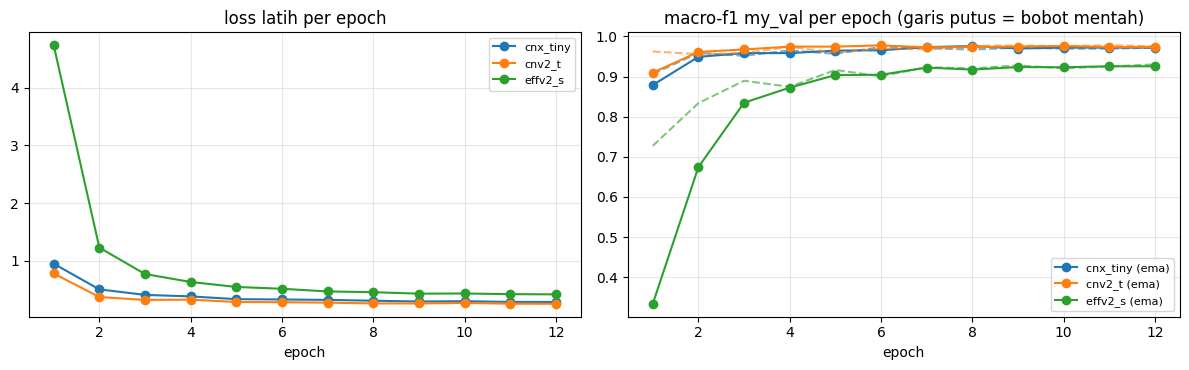

In [18]:
# tabel perbandingan run
infos = {e['tag']: baca_info(e['tag']) for e in experiments}
tabel_run = pd.DataFrame([{
    'run': t, 'backbone': i['backbone'], 'param_juta': round(i['n_param'] / 1e6, 1), 'mib_fp16': i['mib_fp16'],
    'f1_last': round(i['f1_last'], 4), 'f1_mean_last3': round(i['f1_mean_last3'], 4),
    'f1_mentah_last': round(i['f1_raw_last'], 4), 'acc_last': round(i['acc_last'], 4),
    'menit': i['menit'], 'n_exclude': i['n_exclude'], 'n_val': i['n_val']} for t, i in infos.items()])
display(tabel_run)

if len({i['n_exclude'] for i in infos.values()}) > 1 or len({i['n_val'] for i in infos.values()}) > 1:
    print('peringatan: data latih atau val antar run berbeda, jalankan ulang run yang tertinggal')

# kurva belajar
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for t in infos:
    h = pd.read_csv(runs_dir / t / 'log.csv')
    axs[0].plot(h.epoch, h.train_loss, marker='o', label=t)
    g = axs[1].plot(h.epoch, h.f1_ema, marker='o', label=f'{t} (ema)')
    axs[1].plot(h.epoch, h.f1_raw, linestyle='--', alpha=.6, color=g[0].get_color())
axs[0].set_title('loss latih per epoch')
axs[1].set_title('macro-f1 my_val per epoch (garis putus = bobot mentah)')
for ax in axs:
    ax.set_xlabel('epoch')
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [19]:
# scan kombinasi ensemble (rata-rata probabilitas)
tags_semua = [e['tag'] for e in experiments]
assert len({infos[t]['img_size'] for t in tags_semua}) == 1, 'ensemble butuh satu resolusi untuk semua anggota'
probs = {t: np.load(runs_dir / t / 'val_probs.npy') for t in tags_semua}
y_val_arr = np.load(runs_dir / tags_semua[0] / 'val_labels.npy')

baris = []
for r in range(2, len(tags_semua) + 1):
    for kombinasi in combinations(tags_semua, r):
        p = np.mean([probs[t] for t in kombinasi], axis=0)
        baris.append(dict(kombinasi=' + '.join(kombinasi), tags=list(kombinasi), f1=macro_f1(y_val_arr, p),
                          acc=float(accuracy_score(y_val_arr, p.argmax(1))),
                          mib=round(sum(infos[t]['mib_fp16'] for t in kombinasi), 1)))
tabel_ens = pd.DataFrame(baris).sort_values('f1', ascending=False).reset_index(drop=True)
display(tabel_ens.drop(columns='tags').round(4))
print('catatan: memilih kombinasi terbaik dari beberapa pilihan di my_val sedikit optimis, itu sebabnya ada margin')

,kombinasi,f1,acc,mib
0,cnx_tiny + cnv2_t,0.9802,0.9806,106.3
1,cnx_tiny + cnv2_t + effv2_s,0.9771,0.9782,144.8
2,cnv2_t + effv2_s,0.9756,0.9758,91.7
3,cnx_tiny + effv2_s,0.9724,0.9734,91.6


catatan: memilih kombinasi terbaik dari beberapa pilihan di my_val sedikit optimis, itu sebabnya ada margin


dibuang karena ukuran > 95 mib: cnx_tiny + cnv2_t (f1 0.9802, 106.3 mib)
dibuang karena ukuran > 95 mib: cnx_tiny + cnv2_t + effv2_s (f1 0.9771, 144.8 mib)
kontrol         : cnx_tiny f1 0.9720
kandidat terbaik: cnv2_t + effv2_s f1 0.9756
pemenang        : cnx_tiny
alasan          : kandidat terbaik (cnv2_t + effv2_s) hanya +0.0036 dari kontrol, tidak melewati margin 0.005, jadi kontrol dipertahankan


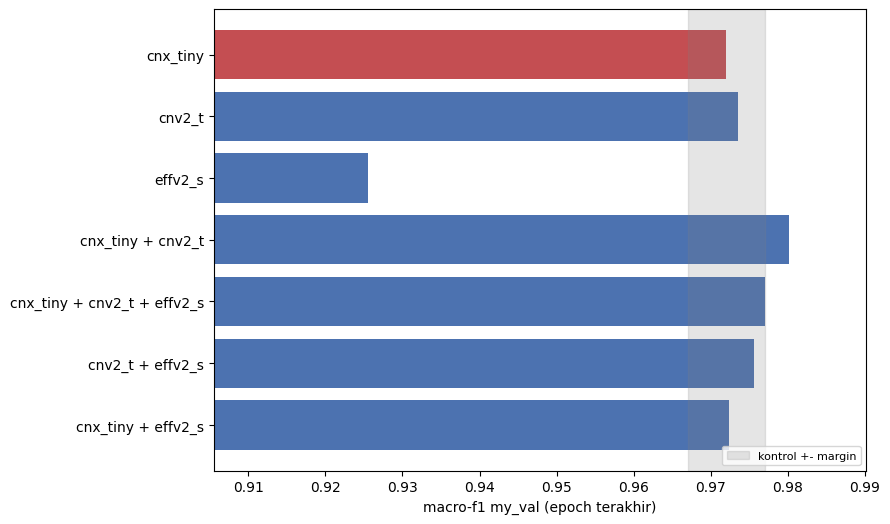

In [20]:
# keputusan: pilih pemenang
f1_kontrol = infos[tag_kontrol]['f1_last']
kandidat = [dict(nama=t, tags=[t], f1=infos[t]['f1_last'], mib=infos[t]['mib_fp16']) for t in tags_semua if t != tag_kontrol]
kandidat += [dict(nama=r.kombinasi, tags=r.tags, f1=r.f1, mib=r.mib) for r in tabel_ens.itertuples()]
# batas ukuran model (mib), di luar cfg agar run tidak dilatih ulang
# 95 = muat github biasa (dipakai). 110 = ensemble lewat git lfs / release
batas_keputusan_mib = 95
dibuang = [k for k in kandidat if k['mib'] > batas_keputusan_mib]
muat = [k for k in kandidat if k['mib'] <= batas_keputusan_mib]
for k in dibuang:
    print(f'dibuang karena ukuran > {batas_keputusan_mib} mib: {k["nama"]} (f1 {k["f1"]:.4f}, {k["mib"]} mib)')
terbaik = max(muat, key=lambda k: k['f1'])
selisih = terbaik['f1'] - f1_kontrol

if selisih > cfg['margin']:
    pemenang = terbaik
    alasan = f'{terbaik["nama"]} menang {selisih:+.4f} dari kontrol, di atas margin {cfg["margin"]}'
else:
    pemenang = dict(nama=tag_kontrol, tags=[tag_kontrol], f1=f1_kontrol, mib=infos[tag_kontrol]['mib_fp16'])
    alasan = (f'kandidat terbaik ({terbaik["nama"]}) hanya {selisih:+.4f} dari kontrol, '
              f'tidak melewati margin {cfg["margin"]}, jadi kontrol dipertahankan')

print(f'kontrol         : {tag_kontrol} f1 {f1_kontrol:.4f}')
print(f'kandidat terbaik: {terbaik["nama"]} f1 {terbaik["f1"]:.4f}')
print(f'pemenang        : {pemenang["nama"]}')
print('alasan          :', alasan)

fig, ax = plt.subplots(figsize=(9, 0.55 * (len(kandidat) + 1) + 1.5))
nama = [tag_kontrol] + [k['nama'] for k in kandidat]
nilai = [f1_kontrol] + [k['f1'] for k in kandidat]
ax.barh(nama[::-1], nilai[::-1], color=['#4c72b0' if n != pemenang['nama'] else '#c44e52' for n in nama[::-1]])
ax.axvspan(f1_kontrol - cfg['margin'], f1_kontrol + cfg['margin'], color='gray', alpha=.2, label='kontrol +- margin')
ax.set_xlim(min(nilai) - 0.02, max(nilai) + 0.01)
ax.set_xlabel('macro-f1 my_val (epoch terakhir)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 10. analisis pemenang

classification report, confusion matrix, dan contoh salah prediksi di `my_val`.

pemenang: cnx_tiny | macro-f1 0.9720 | akurasi 0.9734
               precision    recall  f1-score   support

botol_plastik     0.9512    1.0000    0.9750        78
gelas_plastik     0.9868    0.9615    0.9740        78
kertas_kardus     0.9167    1.0000    0.9565        55
saset_kemasan     0.9899    0.9703    0.9800       101
    styrofoam     1.0000    0.9505    0.9746       101

     accuracy                         0.9734       413
    macro avg     0.9689    0.9765    0.9720       413
 weighted avg     0.9747    0.9734    0.9735       413



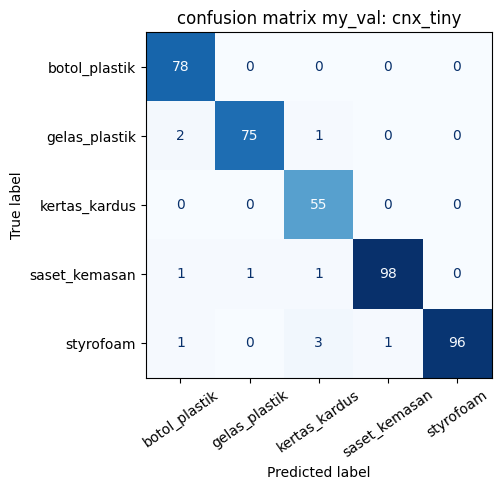

In [21]:
# laporan dan confusion matrix pemenang
p_win = np.mean([probs[t] for t in pemenang['tags']], axis=0)
pred_win = p_win.argmax(1)
print(f'pemenang: {pemenang["nama"]} | macro-f1 {macro_f1(y_val_arr, p_win):.4f} | akurasi {accuracy_score(y_val_arr, pred_win):.4f}')
laporan = classification_report(y_val_arr, pred_win, target_names=kelas, digits=4, zero_division=0, output_dict=True)
print(classification_report(y_val_arr, pred_win, target_names=kelas, digits=4, zero_division=0))

cm = confusion_matrix(y_val_arr, pred_win, labels=list(range(n_kelas)))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=kelas).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=35)
ax.set_title(f'confusion matrix my_val: {pemenang["nama"]}')
plt.tight_layout()
plt.show()

pd.DataFrame(dict(file=[rel_path(it) for it in val_dipakai], asli=[kelas[i] for i in y_val_arr],
                  prediksi=[kelas[i] for i in pred_win], yakin=p_win.max(1).round(4),
                  benar=pred_win == y_val_arr)).to_csv(runs_dir / 'val_predictions_pemenang.csv', index=False)

## 11. latih ulang pemenang

latih ulang pemenang di semua data (train + `my_val`), resep dan epoch sama.

In [23]:
# latih ulang pemenang di semua data
exp_by_tag = {e['tag']: e for e in experiments}
infos_full = {}
for t in pemenang['tags']:
    infos_full[t] = jalankan(exp_by_tag[t], full=True)
    print(t, '-> n_train', infos_full[t]['n_train'], '| menit', infos_full[t]['menit'])

[cnx_tiny_full] memakai hasil tersimpan (konfigurasi sama)
cnx_tiny -> n_train 2753 | menit 7.1


## 12. ekspor submission

buat `submission/` (`model.py`, `model.pth`, `requirements.txt`), lalu uji dengan `evaluate.py`.

In [24]:
# isi model.py dan fungsi ekspor
model_py = '''# submission studio 2 · kelompok 13 (k13b - synapse)
# get_model() = arsitektur saja, bobot dimuat evaluate.py
# urutan kelas: 0 botol_plastik, 1 gelas_plastik, 2 kertas_kardus, 3 saset_kemasan, 4 styrofoam
import torch
import torch.nn as nn
import timm
from torchvision import transforms
from torchvision.transforms import InterpolationMode

n_kelas = 5
arsitektur = @arsitektur@
ukuran = @ukuran@
rata = @rata@
simpangan = @simpangan@


class gabungan(nn.Module):
    def __init__(self, nama_arsitektur):
        super().__init__()
        self.anggota = nn.ModuleList(
            [timm.create_model(a, pretrained=False, num_classes=n_kelas) for a in nama_arsitektur]
        )

    def forward(self, x):
        # normalisasi per anggota (mean/std bisa beda)
        keluaran = []
        for m, mu, sd in zip(self.anggota, rata, simpangan):
            mu_t = torch.tensor(mu, dtype=x.dtype, device=x.device).view(1, 3, 1, 1)
            sd_t = torch.tensor(sd, dtype=x.dtype, device=x.device).view(1, 3, 1, 1)
            keluaran.append(m((x - mu_t) / sd_t).float())
        if len(keluaran) == 1:
            return keluaran[0]
        prob = torch.stack([k.softmax(dim=-1) for k in keluaran]).mean(dim=0)
        return prob.clamp_min(1e-8).log()


def get_model():
    return gabungan(arsitektur)


def get_transform():
    return transforms.Compose([
        transforms.Resize((ukuran, ukuran), interpolation=InterpolationMode.BICUBIC),
        transforms.ToTensor(),
    ])
'''

def muat_modul(dest):
    spec = importlib.util.spec_from_file_location('submission_model', Path(dest).resolve() / 'model.py')
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

def ekspor(tags_run, dest, fp16=True):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    daftar = [baca_info(t) for t in tags_run]
    assert len({i['img_size'] for i in daftar}) == 1, 'resolusi anggota harus sama'
    isi = (model_py.replace('@arsitektur@', repr([i['backbone'].split('.')[0] for i in daftar]))
                   .replace('@ukuran@', repr(daftar[0]['img_size']))
                   .replace('@rata@', repr([tuple(i['mean']) for i in daftar]))
                   .replace('@simpangan@', repr([tuple(i['std']) for i in daftar])))
    (dest / 'model.py').write_text(isi)
    (dest / 'requirements.txt').write_text('timm>=1.0\n')

    model = muat_modul(dest).get_model()
    for anggota, t in zip(model.anggota, tags_run):
        state = torch.load(runs_dir / t / 'ema.pth', map_location='cpu', weights_only=True)
        anggota.load_state_dict(state, strict=True)
    state = {k: (v.half() if (fp16 and v.is_floating_point()) else v) for k, v in model.state_dict().items()}
    torch.save(state, dest / 'model.pth')
    mib = (dest / 'model.pth').stat().st_size / 2 ** 20
    print(f'{dest.name}/model.pth: {mib:.1f} mib')
    if mib > 100:
        print('peringatan: lebih dari 100 mib, lampirkan lewat github release atau git lfs dan tulis tautannya di readme')
    return mib

def uji_evaluate(dest, data='my_val'):
    ev = repo_dir / 'evaluate.py'
    if not ev.exists():
        raise FileNotFoundError('evaluate.py tidak ada di root repo kerja, salin dari starter kit lalu jalankan ulang sel ini')
    hasil = subprocess.run([sys.executable, 'evaluate.py', '--submission', f'./{dest}', '--data', f'./{data}',
                            '--out', f'{dest}_eval.json'], cwd=repo_dir, capture_output=True, text=True)
    print(hasil.stdout)
    if hasil.returncode != 0:
        print(hasil.stderr[-1500:])
        raise RuntimeError('evaluate.py gagal, perbaiki sebelum commit')
    return json.loads((repo_dir / f'{dest}_eval.json').read_text())

In [25]:
# ekspor versi hold-out, cek skor evaluate.py sama dengan notebook
ekspor(pemenang['tags'], repo_dir / 'cek_holdout')
ev_holdout = uji_evaluate('cek_holdout')
print(f'skor notebook   : {macro_f1(y_val_arr, p_win):.4f}')
print(f'skor evaluate.py: {ev_holdout["macro_f1"]:.4f}')
if smoke:
    print('mode smoke: jumlah gambar my_val untuk evaluate.py lebih banyak dari yang dipakai notebook, skor tidak perlu sama')
elif abs(ev_holdout['macro_f1'] - macro_f1(y_val_arr, p_win)) > 0.01:
    print('peringatan: selisih lebih dari 0,01, periksa urutan kelas, transform, atau cara muat bobot')

cek_holdout/model.pth: 53.1 mib
device=cuda  gambar=413

Macro-F1 : 0.9720
Akurasi  : 0.9734
  F1 botol_plastik   0.9750
  F1 gelas_plastik   0.9740
  F1 kertas_kardus   0.9565
  F1 saset_kemasan   0.9800
  F1 styrofoam       0.9746
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [78, 0, 0, 0, 0]
  gelas_plastik   [2, 75, 1, 0, 0]
  kertas_kardus   [0, 0, 55, 0, 0]
  saset_kemasan   [1, 1, 1, 98, 0]
  styrofoam       [1, 0, 3, 1, 96]

skor notebook   : 0.9720
skor evaluate.py: 0.9720


In [26]:
# ekspor versi penuh ke submission/
tags_full = [t + '_full' for t in pemenang['tags']]
mib_submission = ekspor(tags_full, repo_dir / 'submission')
ev_penuh = uji_evaluate('submission')
print('catatan: my_val sudah ikut dilatih pada versi penuh, jadi skor di atas hanya bukti bahwa kontrak submission lolos, bukan estimasi performa')

submission/model.pth: 53.1 mib
device=cuda  gambar=413

Macro-F1 : 1.0000
Akurasi  : 1.0000
  F1 botol_plastik   1.0000
  F1 gelas_plastik   1.0000
  F1 kertas_kardus   1.0000
  F1 saset_kemasan   1.0000
  F1 styrofoam       1.0000
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [78, 0, 0, 0, 0]
  gelas_plastik   [0, 78, 0, 0, 0]
  kertas_kardus   [0, 0, 55, 0, 0]
  saset_kemasan   [0, 0, 0, 101, 0]
  styrofoam       [0, 0, 0, 0, 101]

catatan: my_val sudah ikut dilatih pada versi penuh, jadi skor di atas hanya bukti bahwa kontrak submission lolos, bukan estimasi performa


In [27]:
# estimasi waktu cpu (batas 15 menit)
def cek_waktu_cpu(dest, n=32, total_val=740):
    mod = muat_modul(dest)
    model = mod.get_model().eval()
    tf = mod.get_transform()
    semua_val = sorted(my_val.rglob('*.*'))
    langkah = max(1, len(semua_val) // n)
    files = semua_val[::langkah][:n]
    x = torch.stack([tf(Image.open(f).convert('RGB')) for f in files])
    with torch.no_grad():
        t0 = time.time()
        model(x)
        detik = time.time() - t0
    perkiraan = detik / len(files) * total_val
    print(f'{len(files)} gambar dalam {detik:.1f} detik dengan {torch.get_num_threads()} thread cpu')
    print(f'perkiraan {total_val} gambar: {perkiraan / 60:.1f} menit (batas 15 menit, mesin penilai bisa berbeda)')
    return perkiraan

perkiraan_cpu = cek_waktu_cpu('submission')

32 gambar dalam 6.5 detik dengan 1 thread cpu
perkiraan 740 gambar: 2.5 menit (batas 15 menit, mesin penilai bisa berbeda)


## 13. hasil akhir

simpan ringkasan ke `hasil_akhir.json` dan `readme_hasil.md`, lalu cadangkan ke drive.

In [28]:
# ringkasan hasil akhir
f1_pemenang = float(macro_f1(y_val_arr, p_win))
hasil = dict(
    pemenang=pemenang['nama'],
    backbone=[infos[t]['backbone'] for t in pemenang['tags']],
    alasan_keputusan=alasan,
    my_val=dict(macro_f1=round(f1_pemenang, 4), akurasi=round(float(accuracy_score(y_val_arr, pred_win)), 4),
                n_gambar=int(len(y_val_arr)), f1_per_kelas={k: round(laporan[k]['f1-score'], 4) for k in kelas}),
    kontrol=dict(run=tag_kontrol, macro_f1=round(f1_kontrol, 4)),
    selisih_terhadap_kontrol=round(f1_pemenang - f1_kontrol, 4),
    margin=cfg['margin'],
    ukuran_model_mib=round(mib_submission, 1),
    perkiraan_cpu_menit=round(perkiraan_cpu / 60, 1),
    cfg=cfg,
    n_exclude=len(muat_exclude()),
    versi=dict(torch=torch.__version__, timm=timm.__version__),
    smoke=smoke,
)
(repo_dir / 'hasil_akhir.json').write_text(json.dumps(hasil, indent=2))

{
  "pemenang": "cnx_tiny",
  "my_val": {
    "macro_f1": 0.972,
    "akurasi": 0.9734,
    "n_gambar": 413,
    "f1_per_kelas": {
      "botol_plastik": 0.975,
      "gelas_plastik": 0.974,
      "kertas_kardus": 0.9565,
      "saset_kemasan": 0.98,
      "styrofoam": 0.9746
    }
  },
  "selisih_terhadap_kontrol": 0.0,
  "ukuran_model_mib": 53.1,
  "perkiraan_cpu_menit": 2.5
}

file ditulis: /content/repo_studio2/hasil_akhir.json dan /content/repo_studio2/readme_hasil.md


In [29]:
# cadangkan hasil ke drive (/content hilang jika runtime putus)
cadangan = runs_root / 'hasil_final'
cadangan.mkdir(parents=True, exist_ok=True)
shutil.copytree(repo_dir / 'submission', cadangan / 'submission', dirs_exist_ok=True)
for nama_file in ('hasil_akhir.json', 'readme_hasil.md', 'submission_eval.json'):
    f = repo_dir / nama_file
    if f.exists():
        shutil.copy2(f, cadangan / nama_file)

if 'ev_penuh' in globals():
    print('evaluate.py pada submission/ (kontrak saja, my_val ikut terlatih): macro-f1', ev_penuh.get('macro_f1'))
print('tersalin ke', cadangan)
for p in sorted(cadangan.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(cadangan)}  {p.stat().st_size / 2**20:.1f} mib')

evaluate.py pada submission/ (kontrak saja, my_val ikut terlatih): macro-f1 1.0
tersalin ke /content/drive/MyDrive/studio 2/runs_studio2/hasil_final
  hasil_akhir.json  0.0 mib
  readme_hasil.md  0.0 mib
  submission/__pycache__/model.cpython-313.pyc  0.0 mib
  submission/config.json  0.0 mib
  submission/model.pth  53.1 mib
  submission/model.py  0.0 mib
  submission/requirements.txt  0.0 mib
  submission_eval.json  0.0 mib


In [30]:
# Masuk ke direktori repositori
%cd /content/repo_studio2

# Konfigurasi akun (ganti dengan data Anda)
!git config --global user.email "muhammad.12314020@student.itera.ac.id"
!git config --global user.name "Muhammad Piela nugraha"

# Commit dan Push
!git add .
!git commit -m "Update otomatis dari Colab"
!git push origin main

/content
[main bbccd61] Update otomatis dari Colab
 4 files changed, 31 insertions(+), 30 deletions(-)
Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 49.17 MiB | 11.44 MiB/s, done.
Total 7 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 4 local objects.
remote: warning: See https://gh.io/lfs for more information.
remote: warning: File submission/model.pth is 53.11 MB; this is larger than GitHub's recommended maximum file size of 50.00 MB
remote: warning: GH001: Large files detected. You may want to try Git Large File Storage - https://git-lfs.github.com.
To https://github.com/EL-graha26/Kelompok13-ProjeckStudio02.git
   c83a437..bbccd61  main -> main
